# Site figures

Drawn from `results/multiday_summary.csv` (21 regular sessions of ESZ6, 18 Sep to 16 Oct 2026). Presentation only.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "figures" / "site"
OUT.mkdir(parents=True, exist_ok=True)

BLUE, RED, GREY, LIGHT = "#2166ac", "#b2182b", "#8c8c8c", "#d9d9d9"
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Inter", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#444444",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#eeeeee",
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "figure.dpi": 100,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
})


def titled(ax, title, sub=None):
    ax.set_title(title, pad=24 if sub else 10)
    if sub:
        ax.text(0, 1.02, sub, transform=ax.transAxes, fontsize=10, color="#555555", va="bottom")


def save(fig, name):
    fig.savefig(OUT / name, facecolor="white")
    plt.show()


## Daily PnL against ES's move

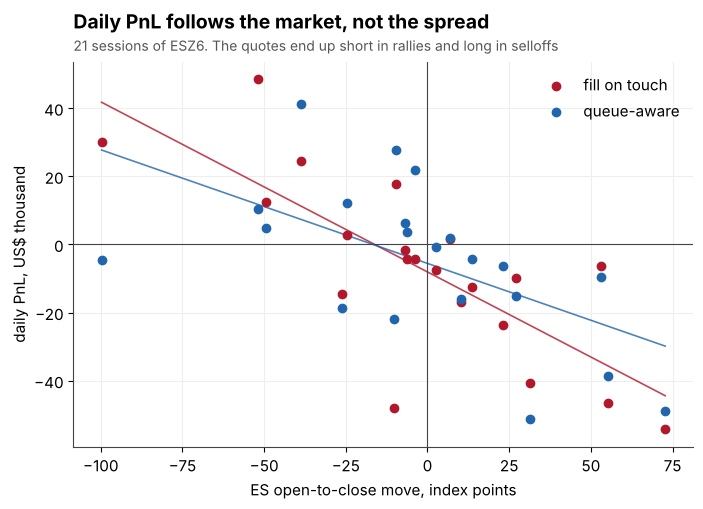

In [2]:
d = pd.read_csv(ROOT / "results/multiday_summary.csv", parse_dates=["day"])
fig, ax = plt.subplots(figsize=(8, 5))
for rule, col, lab in [("touch", RED, "fill on touch"), ("queue-behind", BLUE, "queue-aware")]:
    x = d[d.rule == rule]
    ax.scatter(x.es_oc_pts, x.pnl_usd / 1000, color=col, s=36, label=lab, zorder=3)
    b, a = np.polyfit(x.es_oc_pts, x.pnl_usd / 1000, 1)
    xs = np.linspace(d.es_oc_pts.min(), d.es_oc_pts.max(), 50)
    ax.plot(xs, a + b * xs, color=col, lw=1.2, alpha=0.8)
ax.axhline(0, color="#444444", lw=0.8)
ax.axvline(0, color="#444444", lw=0.8)
ax.set_xlabel("ES open-to-close move, index points")
ax.set_ylabel("daily PnL, US$ thousand")
ax.legend(frameon=False)
titled(ax, "Daily PnL follows the market, not the spread",
       "21 sessions of ESZ6. The quotes end up short in rallies and long in selloffs")
save(fig, "pnl_vs_move.png")

## Mean daily PnL by fill rule

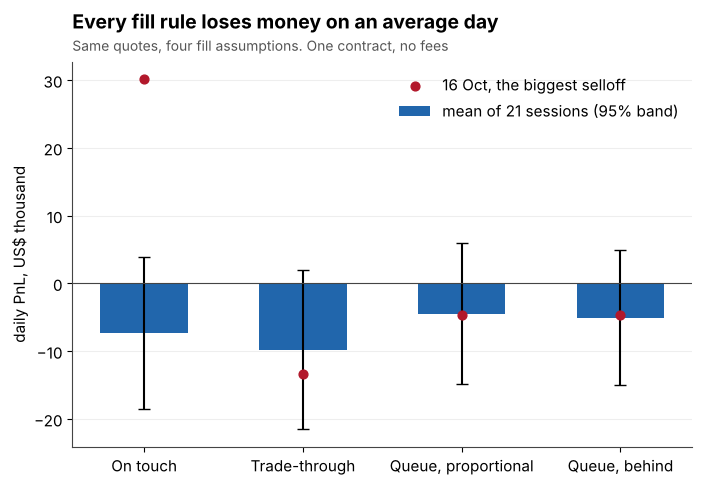

In [3]:
rules = ["touch", "through", "queue-proportional", "queue-behind"]
names = ["On touch", "Trade-through", "Queue, proportional", "Queue, behind"]
m = d.groupby("rule").pnl_usd.agg(["mean", "std", "count"]).loc[rules]
se = m["std"] / np.sqrt(m["count"])
best = d[d.day == d.day.max()].set_index("rule").pnl_usd.loc[rules]
fig, ax = plt.subplots(figsize=(8, 5))
xpos = np.arange(len(rules))
ax.bar(xpos, m["mean"] / 1000, yerr=1.96 * se / 1000, color=BLUE, width=0.55, capsize=4, label="mean of 21 sessions (95% band)")
ax.scatter(xpos, best / 1000, color=RED, zorder=3, s=40, label="16 Oct, the biggest selloff")
ax.axhline(0, color="#444444", lw=0.8)
ax.set_xticks(xpos, names)
ax.set_ylabel("daily PnL, US$ thousand")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper right")
titled(ax, "Every fill rule loses money on an average day",
       "Same quotes, four fill assumptions. One contract, no fees")
save(fig, "pnl_by_rule.png")